In [1]:
# Global Imports and Visual Settings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OrdinalEncoder

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 4)

print("Libraries for Ordinal and Frequency Encoding loaded successfully.")

Libraries for Ordinal and Frequency Encoding loaded successfully.


# Table of Contents
- 1. What is Ordinal Encoding? (Preserving Natural Hierarchy)
- 2. Simple Example: Education Levels (Pandas Mapping)
- 3. Production Pipeline with Scikit-Learn (`OrdinalEncoder`)
- 4. What is Frequency (Count) Encoding? (Handling High Cardinality)
- 5. Simple Example: Customer Cities (Frequency Normalization)
- 6. Summary Comparison: One-Hot vs Ordinal vs Frequency Encoding
- 7. 🎯 Critical Interview Traps, Viva Hacks & Things to Learn

## 1. What is Ordinal Encoding? (Preserving Natural Hierarchy)

**Ordinal Data** refers to categorical variables that possess a meaningful, natural ranking or order:
$$\text{Low} < \text{Medium} < \text{High}$$
$$\text{High School} < \text{Bachelor's} < \text{Master's} < \text{PhD}$$
$$\text{Bronze} < \text{Silver} < \text{Gold} < \text{Platinum}$$

In **Ordinal Encoding**, each category is converted into an integer reflecting its exact position in the hierarchy:
$$\text{Mapping: } c_i \mapsto i, \quad \text{where } c_1 < c_2 < \dots < c_K$$

### Why Not One-Hot Encoding for Ordinal Data?
- One-Hot Encoding treats all categories as equidistant and independent, **discarding the valuable order information** ($1 < 2 < 3$).
- Ordinal Encoding preserves this progression while adding only **1 single column**, keeping memory low.

In [2]:
# 2. Simple Example: Employee Education Level
df_employee = pd.DataFrame({
    'employee_id': [101, 102, 103, 104, 105, 106],
    'education': ['High School', 'Bachelor', 'Master', 'PhD', 'Bachelor', 'High School'],
    'experience_years': [2, 4, 7, 10, 5, 1],
    'salary': [35000, 55000, 85000, 115000, 62000, 32000]
})

print("Original Employee Dataset:")
print(df_employee)
print("_" * 60)

# Define explicit natural ordering
education_hierarchy = {
    'High School': 1,
    'Bachelor': 2,
    'Master': 3,
    'PhD': 4
}

# Apply explicit dictionary mapping
df_employee['education_encoded'] = df_employee['education'].map(education_hierarchy)

print("Ordinal Encoded Dataset (Order: High School=1 < Bachelor=2 < Master=3 < PhD=4):")
print(df_employee[['employee_id', 'education', 'education_encoded', 'salary']])

Original Employee Dataset:
   employee_id    education  experience_years  salary
0          101  High School                 2   35000
1          102     Bachelor                 4   55000
2          103       Master                 7   85000
3          104          PhD                10  115000
4          105     Bachelor                 5   62000
5          106  High School                 1   32000
____________________________________________________________
Ordinal Encoded Dataset (Order: High School=1 < Bachelor=2 < Master=3 < PhD=4):
   employee_id    education  education_encoded  salary
0          101  High School                  1   35000
1          102     Bachelor                  2   55000
2          103       Master                  3   85000
3          104          PhD                  4  115000
4          105     Bachelor                  2   62000
5          106  High School                  1   32000


## 3. Production Pipeline with Scikit-Learn (`OrdinalEncoder`)

In machine learning pipelines, we use Scikit-Learn's `OrdinalEncoder`. 

> ⚠️ **CRITICAL WARNING:** By default, `OrdinalEncoder()` orders categories **alphabetically** (`'Bachelor' -> 0`, `'High School' -> 1`, `'Master' -> 2`, `'PhD' -> 3`). That would wrongly make Bachelor's lower than High School!  
> **Always pass explicit ordered categories:** `categories=[['High School', 'Bachelor', 'Master', 'PhD']]`.

In [3]:
# Explicit Scikit-Learn OrdinalEncoder
ordered_categories = [['High School', 'Bachelor', 'Master', 'PhD']]

encoder = OrdinalEncoder(categories=ordered_categories)
df_employee['sklearn_encoded'] = encoder.fit_transform(df_employee[['education']])

print("Scikit-Learn Explicit Ordinal Encoding:")
print(df_employee[['education', 'education_encoded', 'sklearn_encoded']])
print("_" * 60)
print("Encoder Categories List:", encoder.categories_)

Scikit-Learn Explicit Ordinal Encoding:
     education  education_encoded  sklearn_encoded
0  High School                  1              0.0
1     Bachelor                  2              1.0
2       Master                  3              2.0
3          PhD                  4              3.0
4     Bachelor                  2              1.0
5  High School                  1              0.0
____________________________________________________________
Encoder Categories List: [array(['High School', 'Bachelor', 'Master', 'PhD'], dtype=object)]


## 4. What is Frequency (Count) Encoding? (Handling High Cardinality)

### The Problem: High Cardinality Nominal Data
Suppose a dataset has a feature like `city`, `zip_code`, or `product_brand` with hundreds or thousands of categories:
- One-Hot Encoding would create 500+ sparse columns, causing the **Curse of Dimensionality** and memory exhaustion.
- Ordinal Encoding is invalid because cities (`Mumbai`, `Delhi`, `Pune`) have no natural mathematical hierarchy (`Mumbai < Delhi` is meaningless).

---

### The Solution: Frequency (Count) Encoding
**Frequency Encoding** replaces each category with its percentage frequency (or count) in the dataset:

$$\text{Frequency}(C) = \frac{\text{Count}(C)}{N}$$

- Frequently occurring categories receive **higher values**.
- Rare categories receive **lower values** near 0.
- Adds only **1 single numeric column**, solving the curse of dimensionality!

In [4]:
# 5. Simple Example: Customer Orders by City
np.random.seed(42)

df_customers = pd.DataFrame({
    'order_id': range(1001, 1011),
    'city': ['Mumbai', 'Delhi', 'Mumbai', 'Bengaluru', 'Mumbai', 'Delhi', 'Pune', 'Mumbai', 'Bengaluru', 'Delhi'],
    'order_amount': [120, 85, 230, 45, 310, 150, 95, 180, 210, 115]
})

print("Original Customer Orders:")
print(df_customers.head(5))
print("_" * 60)

# Calculate Normalized Frequencies (Proportion of total rows)
city_frequency_map = df_customers['city'].value_counts(normalize=True).round(3)
print("Frequency Distribution Map (Normalized):")
print(city_frequency_map)
print("_" * 60)

# Map frequency back into DataFrame
df_customers['city_frequency'] = df_customers['city'].map(city_frequency_map)

print("Dataset with Frequency Encoding:")
print(df_customers[['order_id', 'city', 'city_frequency', 'order_amount']])

Original Customer Orders:
   order_id       city  order_amount
0      1001     Mumbai           120
1      1002      Delhi            85
2      1003     Mumbai           230
3      1004  Bengaluru            45
4      1005     Mumbai           310
____________________________________________________________
Frequency Distribution Map (Normalized):
city
Mumbai       0.4
Delhi        0.3
Bengaluru    0.2
Pune         0.1
Name: proportion, dtype: float64
____________________________________________________________
Dataset with Frequency Encoding:
   order_id       city  city_frequency  order_amount
0      1001     Mumbai             0.4           120
1      1002      Delhi             0.3            85
2      1003     Mumbai             0.4           230
3      1004  Bengaluru             0.2            45
4      1005     Mumbai             0.4           310
5      1006      Delhi             0.3           150
6      1007       Pune             0.1            95
7      1008     Mumbai    

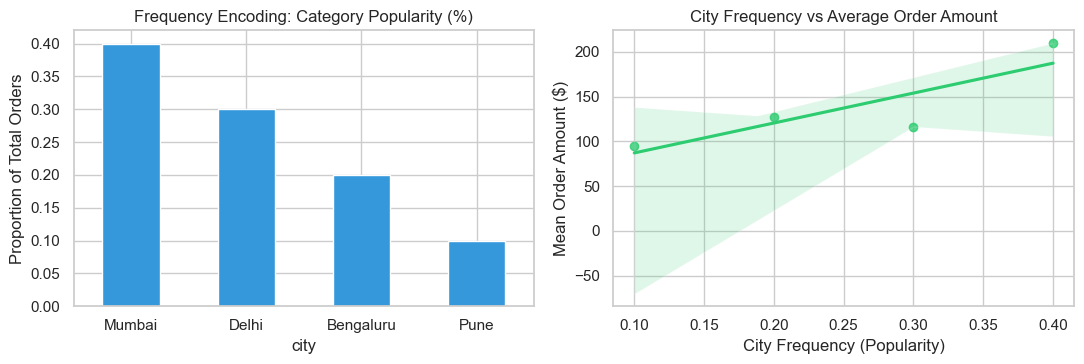

In [5]:
# Visualizing Frequency vs Target Metric
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

# Plot 1: City Frequency Distribution
city_frequency_map.plot(kind='bar', color='#3498db', ax=axes[0], rot=0)
axes[0].set_title('Frequency Encoding: Category Popularity (%)')
axes[0].set_ylabel('Proportion of Total Orders')

# Plot 2: Relationship between City Frequency and Average Order Amount
city_avg_order = df_customers.groupby('city_frequency')['order_amount'].mean().reset_index()
sns.regplot(x='city_frequency', y='order_amount', data=city_avg_order, color='#2ecc71', ax=axes[1])
axes[1].set_title('City Frequency vs Average Order Amount')
axes[1].set_xlabel('City Frequency (Popularity)')
axes[1].set_ylabel('Mean Order Amount ($)')

plt.tight_layout()
plt.show()

## 6. Summary Comparison: One-Hot vs Ordinal vs Frequency Encoding

| Feature Dimension | One-Hot Encoding (OHE) | Ordinal Encoding | Frequency (Count) Encoding |
| :--- | :--- | :--- | :--- |
| **Input Data Type** | Nominal (No natural order) | Ordinal (Inherent order) | Nominal with High Cardinality |
| **Output Columns** | $K$ (or $K-1$ for dummy) | **1 Column** | **1 Column** |
| **Order Assumption** | No order ($1 < 2$ not assumed) | Strict Order ($1 < 2 < 3$) | Implicit Order by Popularity |
| **Memory Consumption** | High (creates sparse matrix) | Extremely Low | Extremely Low |
| **Best Use Cases** | Categories $< 10$ (Gender, Device) | Ratings, Education, Sizes | High cardinality (Zip codes, Cities) |
| **Implementation** | `pd.get_dummies()`, `OneHotEncoder` | `df.map()`, `OrdinalEncoder` | `df['col'].value_counts(normalize=True)` |

## 7. 🎯 Critical Interview Traps, Viva Hacks & Things to Learn

---

### ⚠️ Top Interview Traps for Ordinal & Frequency Encoding

#### 🛑 Trap 1: The Scikit-Learn Alphabetical Ordering Trap
- **The Question:** *"What happens if you run `OrdinalEncoder().fit_transform(df[['education']])` without specifying categories?"*
- **The Disaster:** Scikit-Learn sorts unique strings alphabetically:
  $$\text{'Bachelor'} \mapsto 0, \quad \text{'High School'} \mapsto 1, \quad \text{'Master'} \mapsto 2, \quad \text{'PhD'} \mapsto 3$$
  It mathematically asserts that a Bachelor's degree is **less educated** than a High School diploma!
- **The Fix:** ALWAYS pass explicit ordered nested lists: `categories=[['High School', 'Bachelor', 'Master', 'PhD']]`.

---

#### 🛑 Trap 2: The "Frequency Collision" Problem
- **The Question:** *"What is the primary failure mode of Frequency Encoding?"*
- **The Trap Answer:** *"It leaks target data."* (Incorrect — frequency uses only $X$!).
- **The True Flaw (Collision):** If two completely different categories (e.g. `'Kolkata'` and `'Chennai'`) happen to appear the **exact same number of times** (e.g. 50 orders each), both get mapped to the exact same frequency score (`0.05`). The model cannot differentiate between Kolkata and Chennai!
- **The Fix:** 
  1. Combine Frequency Encoding with Top-N One-Hot Encoding for the most important categories.
  2. Use Target (Mean) Encoding with smoothing.

---

#### 🛑 Trap 3: Handling Unseen Categories in Test Data
- **The Scenario:** In production, a customer places an order from a brand new city `'Jaipur'` that was never in the training data.
- **What happens?** `df_test['city'].map(train_freq)` produces `NaN`!
- **The Fix:** 
  - Fill missing frequencies with `0` or the minimum training frequency:
  ```python
  df_test['city_freq'] = df_test['city'].map(train_freq).fillna(0)
  ```

---

### 🧠 Golden Rules of Thumb (Mental Checklist)
1. **Never use Ordinal Encoding on Nominal data** (e.g. mapping `Red=1, Green=2, Blue=3` will trick linear models into thinking `Green + Red = Blue`).
2. **Frequency Encoding does NOT cause Target Leakage** because it depends solely on feature counts ($X$), never on the label ($Y$).
3. **For Tree Models (LightGBM, XGBoost, CatBoost):** Integer ordinal encoding and native categorical handling are preferred over high-dimensional One-Hot matrices.